# Student Depression Analysis & Prediction
**Course:** Introduction to Data Science, 2nd Year 1st Term — De La Salle Lipa  
**Team Members:** Irish May Pureza, Julia Lois Mendoza, Kent  

---
### Project Goals:
1. **Univariate & Bivariate Exploratory Data Analysis (EDA):** Understand student demographic, academic, and behavioral features and how they relate to Depression.
2. **Correlation & Association Analysis:** Quantify linear correlations for numerical features and association metrics (Cramér's V) for categorical features.
3. **Structured Preprocessing & Feature Engineering:** Clean, map, and encode nominal, ordinal, and boolean features without data leakage.
4. **Machine Learning Model:** Train and validate a Logistic Regression baseline model to predict student depression status with high sensitivity and F1-score.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Styling configuration
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['figure.autolayout'] = True


## 1. Data Ingestion & Overview

In [2]:
# Support both local workspace path and Google Colab path
data_paths = [
    'Student Depression Dataset.csv.xlsx',
    '/content/Student Depression Dataset.csv.xlsx',
    './Student Depression Dataset.csv.xlsx'
]

df = None
for path in data_paths:
    if os.path.exists(path):
        df = pd.read_excel(path)
        print(f"Loaded dataset from: {path}")
        break

if df is None:
    raise FileNotFoundError("Dataset not found. Please upload 'Student Depression Dataset.csv.xlsx'")

print("Dataset Shape:", df.shape)
df.head()


Loaded dataset from: Student Depression Dataset.csv.xlsx
Dataset Shape: (27901, 18)


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33,Visakhapatnam,Student,5,0,8.97,2,0,5-6 hours,Healthy,B.Pharm,Yes,3,1.0,No,1
1,8,Female,24,Bangalore,Student,2,0,5.90,5,0,5-6 hours,Moderate,BSc,No,3,2.0,Yes,0
2,26,Male,31,Srinagar,Student,3,0,7.03,5,0,Less than 5 hours,Healthy,BA,No,9,1.0,Yes,0
3,30,Female,28,Varanasi,Student,3,0,5.59,2,0,7-8 hours,Moderate,BCA,Yes,4,5.0,Yes,1
4,32,Female,25,Jaipur,Student,4,0,8.13,3,0,5-6 hours,Moderate,M.Tech,Yes,1,1.0,No,0


In [3]:
# Column types, non-null counts, and duplicate check
print("Total Duplicates:", df.duplicated().sum())
df.info()


Total Duplicates: 0
<class 'pandas.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  str    
 2   Age                                    27901 non-null  int64  
 3   City                                   27901 non-null  object 
 4   Profession                             27901 non-null  str    
 5   Academic Pressure                      27901 non-null  int64  
 6   Work Pressure                          27901 non-null  int64  
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  int64  
 9   Job Satisfaction                       27901 non-null  int64  
 10  Sleep Duration                         27901 non-null  str   

In [4]:
# Summary statistics for numerical columns
df.describe()


,id,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Financial Stress,Depression
count,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27898.000000,27901.000000
mean,70442.149421,25.822300,3.141214,0.000430,7.656104,2.943837,0.000681,7.156984,3.139867,0.585499
std,40641.175216,4.905687,1.381465,0.043992,1.470707,1.361148,0.044394,3.707642,1.437347,0.492645
min,2.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,35039.000000,21.000000,2.000000,0.000000,6.290000,2.000000,0.000000,4.000000,2.000000,0.000000
50%,70684.000000,25.000000,3.000000,0.000000,7.770000,3.000000,0.000000,8.000000,3.000000,1.000000
75%,105818.000000,30.000000,4.000000,0.000000,8.920000,4.000000,0.000000,10.000000,4.000000,1.000000
max,140699.000000,59.000000,5.000000,5.000000,10.000000,5.000000,4.000000,12.000000,5.000000,1.000000


## 2. Univariate Exploratory Data Analysis (Data Visualization)
Exploring each variable individually to inspect distributions, ranges, and imbalances.


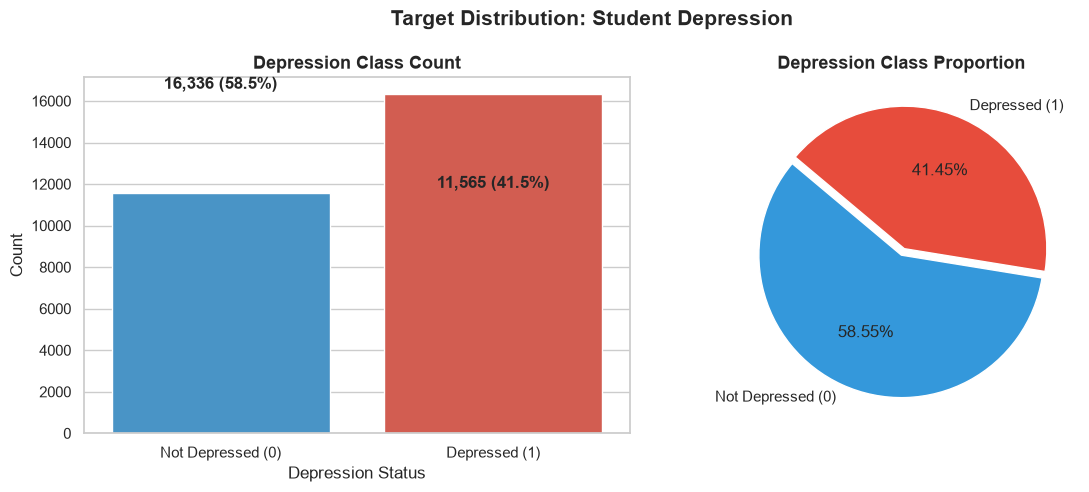

In [5]:
# A. Target Variable Distribution: Depression
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
target_counts = df['Depression'].value_counts()
labels = ['Not Depressed (0)', 'Depressed (1)']
colors = ['#3498db', '#e74c3c']

sns.barplot(x=target_counts.index, y=target_counts.values, palette=colors, ax=axes[0], hue=target_counts.index, legend=False)
axes[0].set_title("Depression Class Count", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Depression Status")
axes[0].set_ylabel("Count")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(labels)
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 250, f"{v:,} ({v / len(df) * 100:.1f}%)", ha='center', fontweight='bold')

axes[1].pie(target_counts, labels=labels, autopct='%1.2f%%', startangle=140, colors=colors, explode=(0, 0.05))
axes[1].set_title("Depression Class Proportion", fontsize=13, fontweight='bold')
plt.suptitle("Target Distribution: Student Depression", fontsize=15, fontweight='bold')
plt.show()


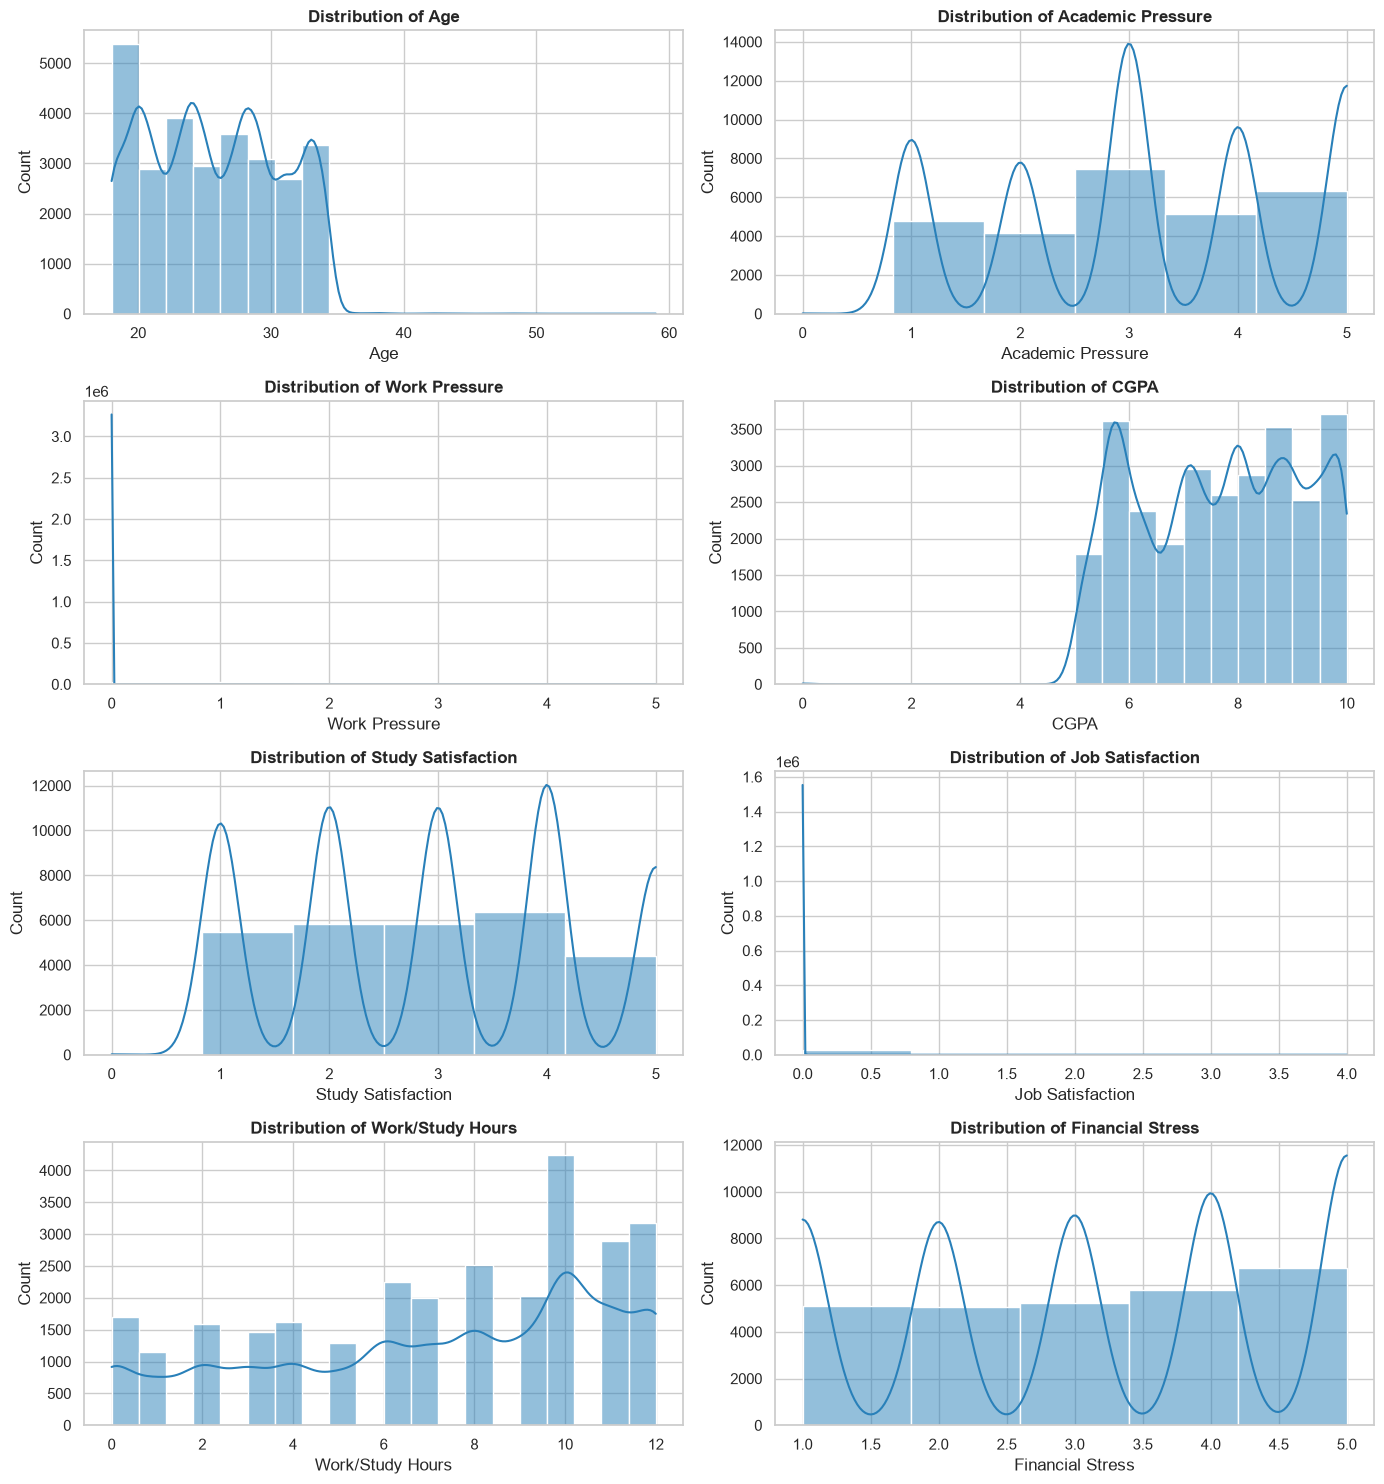

In [6]:
# B. Numerical Variables Distributions
numeric_cols = ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress']

fig, axes = plt.subplots(4, 2, figsize=(14, 15))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[idx], color='#2980b9', bins=20 if df[col].nunique() > 10 else df[col].nunique())
    axes[idx].set_title(f"Distribution of {col}", fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Count")

plt.tight_layout()
plt.show()  


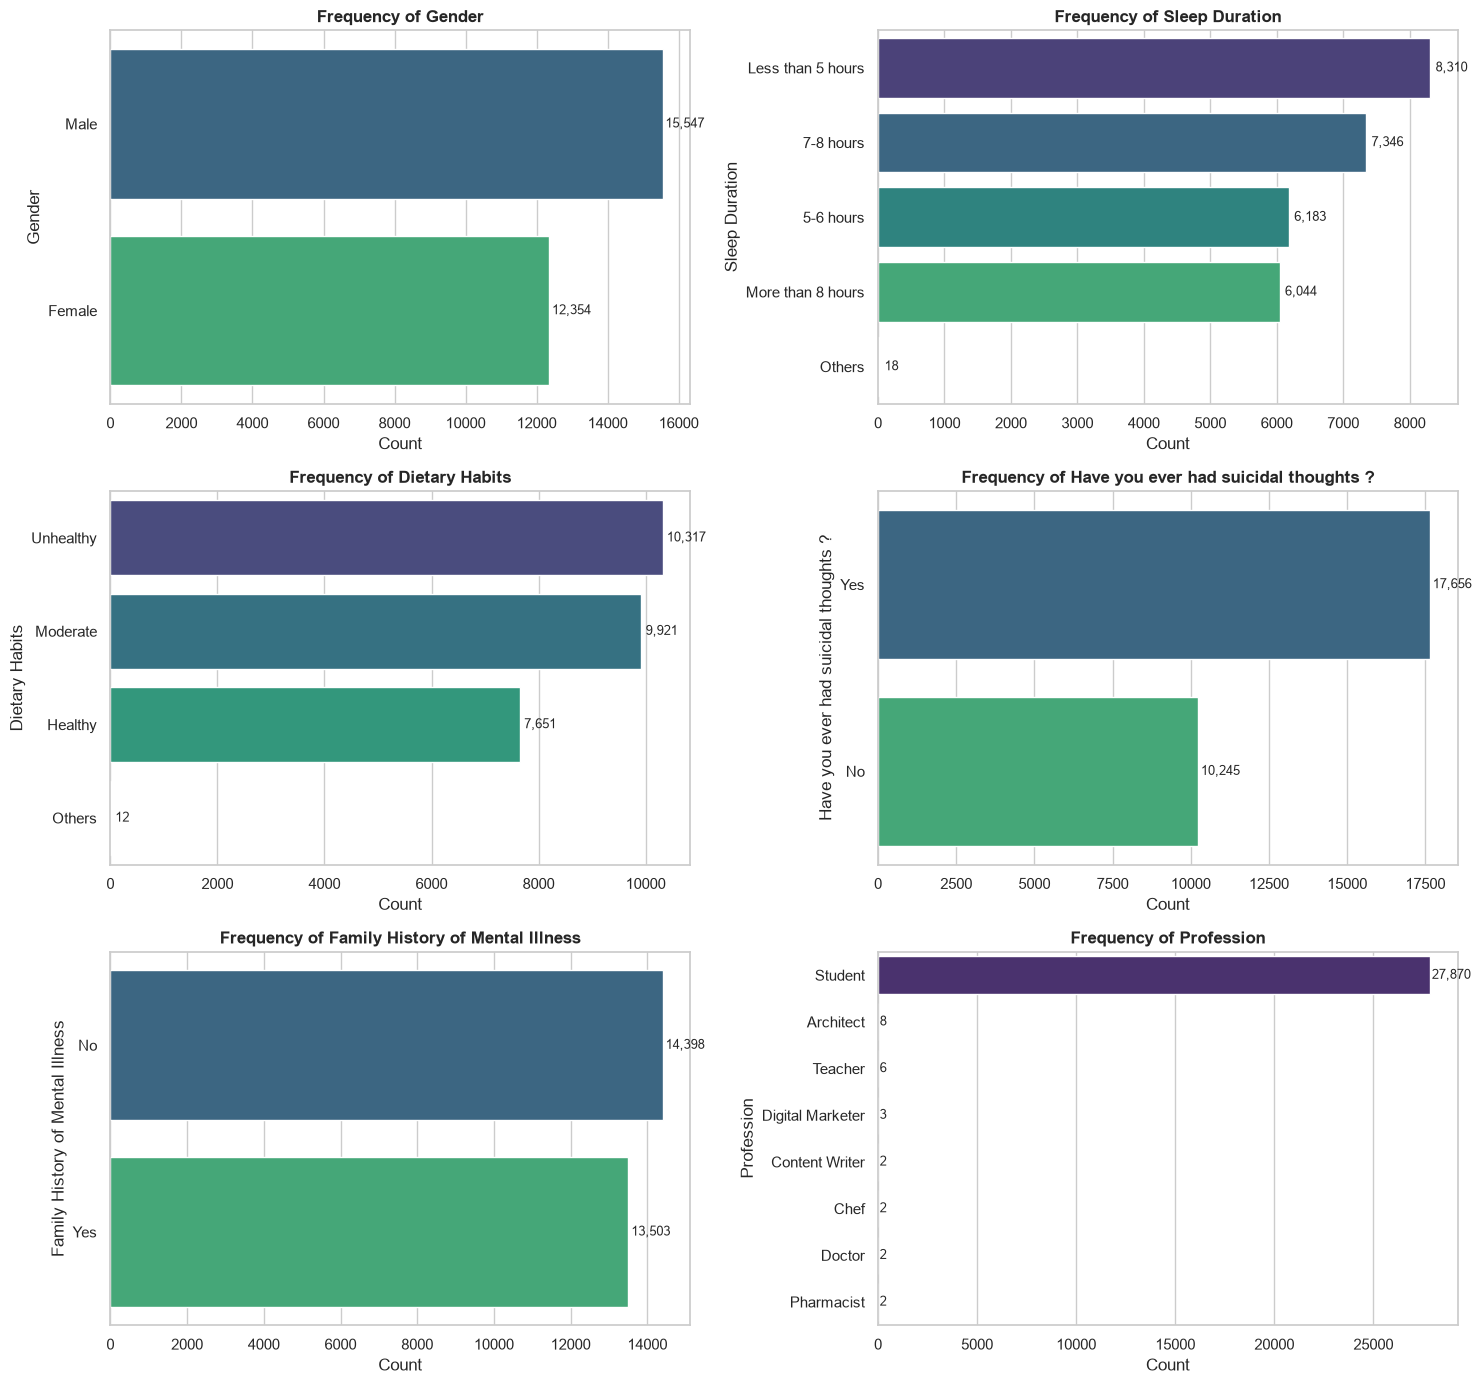

In [7]:
# C. Categorical Variables Distributions
cat_cols = ['Gender', 'Sleep Duration', 'Dietary Habits', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness', 'Profession']

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    top_counts = df[col].value_counts().head(8)
    sns.barplot(y=top_counts.index, x=top_counts.values, ax=axes[idx], palette='viridis', hue=top_counts.index, legend=False)
    axes[idx].set_title(f"Frequency of {col}", fontweight='bold')
    axes[idx].set_xlabel("Count")
    axes[idx].set_ylabel(col)
    for i, v in enumerate(top_counts.values):
        axes[idx].text(v + 80, i, f"{v:,}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 3. Bivariate Exploratory Data Analysis (Features vs Depression)
Analyzing relationships between individual predictors and depression status.


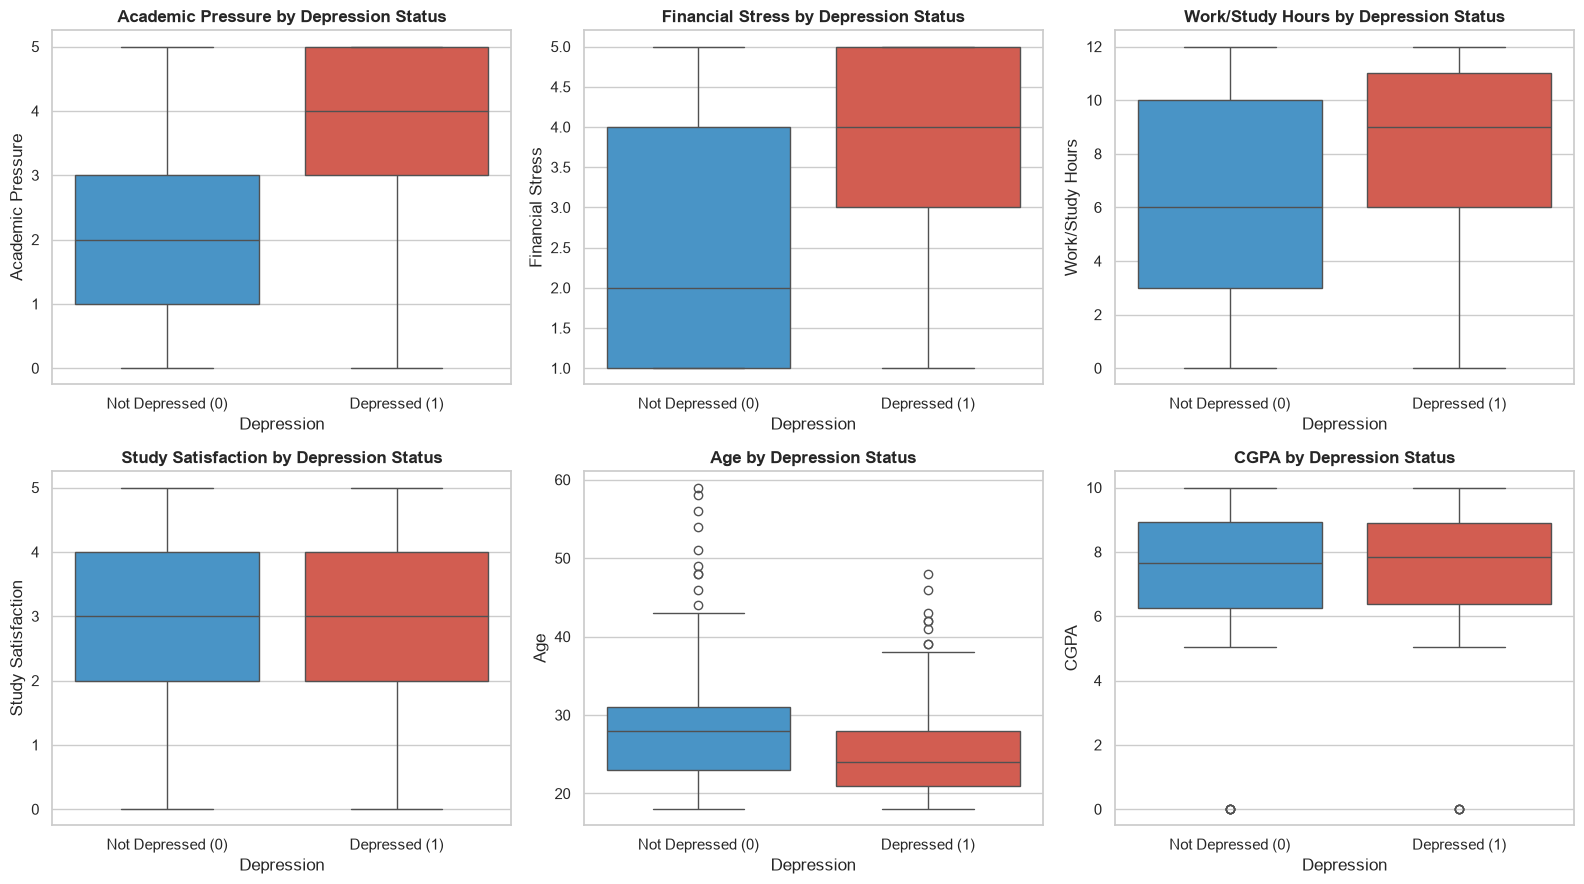

In [8]:
# A. Numerical Features vs Depression Status (Boxplots)
key_numeric = ['Academic Pressure', 'Financial Stress', 'Work/Study Hours', 'Study Satisfaction', 'Age', 'CGPA']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, col in enumerate(key_numeric):
    sns.boxplot(x='Depression', y=col, data=df, palette=['#3498db', '#e74c3c'], ax=axes[idx], hue='Depression', legend=False)
    axes[idx].set_title(f"{col} by Depression Status", fontweight='bold')
    axes[idx].set_xticks([0, 1])
    axes[idx].set_xticklabels(['Not Depressed (0)', 'Depressed (1)'])

plt.tight_layout()
plt.show()


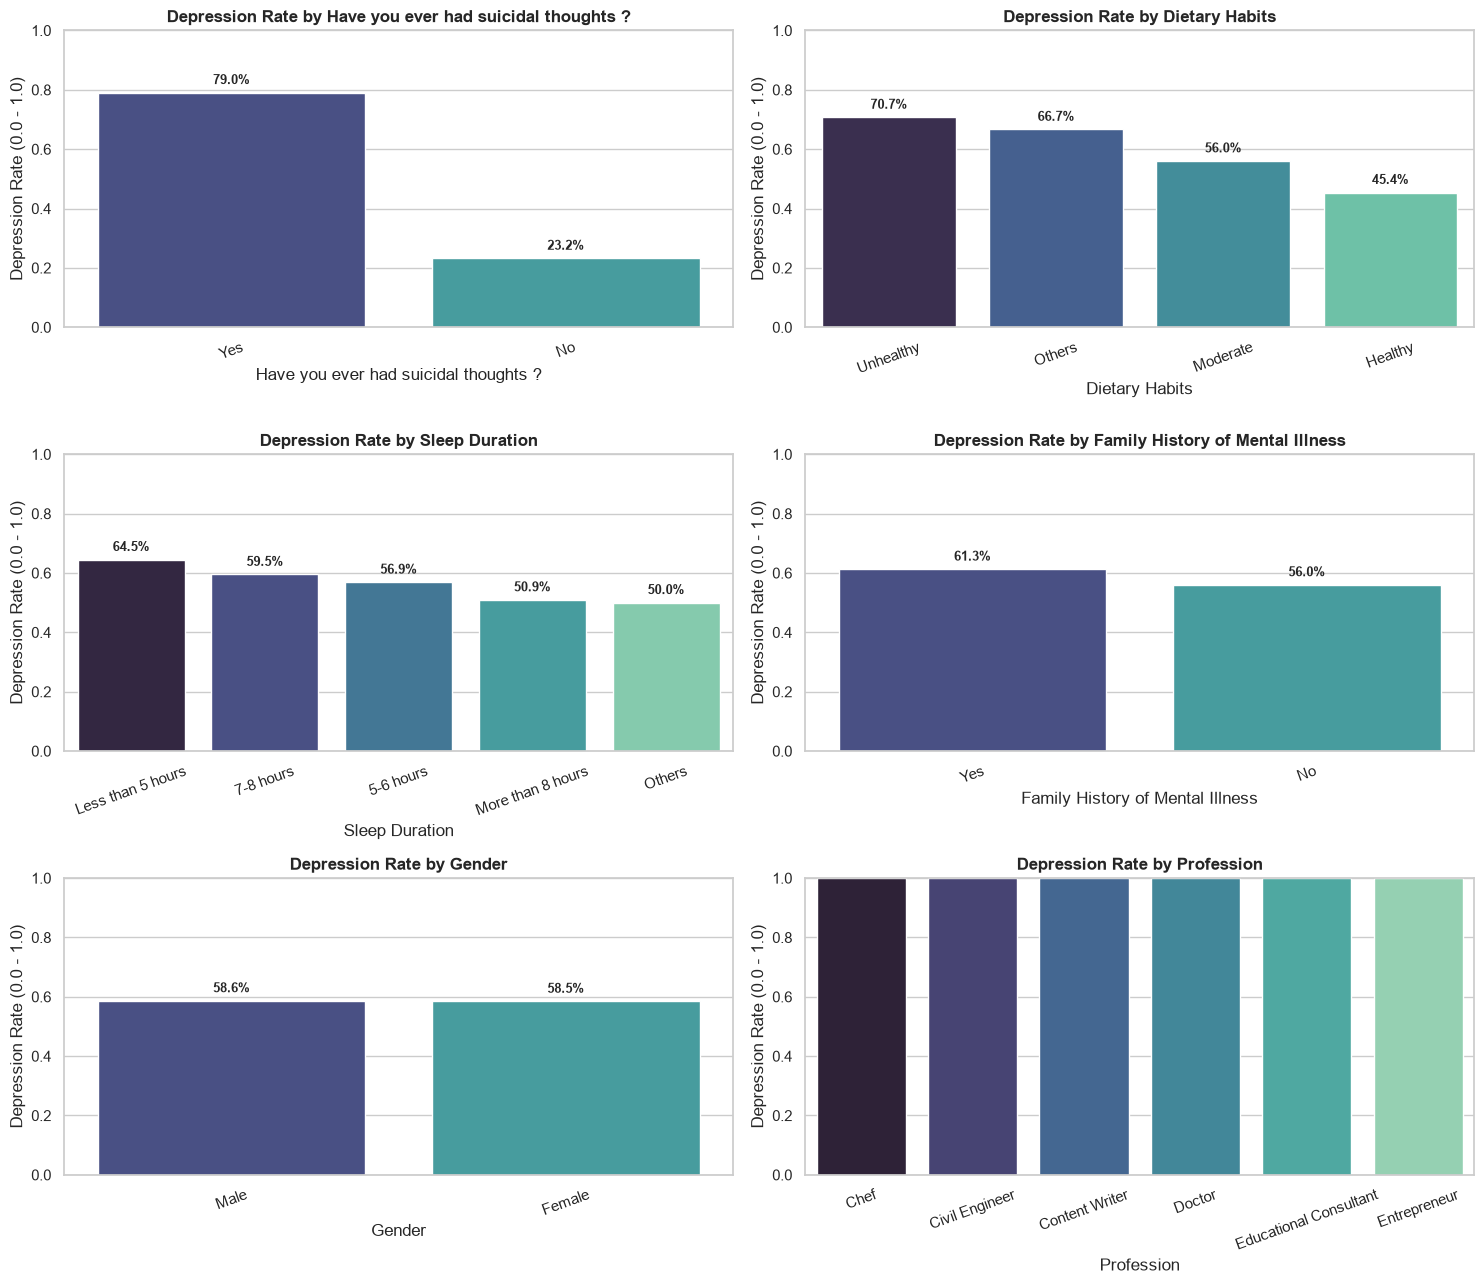

In [9]:
# B. Categorical Predictors vs Depression Rate (%)
key_cat = ['Have you ever had suicidal thoughts ?', 'Dietary Habits', 'Sleep Duration', 'Family History of Mental Illness', 'Gender', 'Profession']

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

for idx, col in enumerate(key_cat):
    dep_rate = df.groupby(col)['Depression'].mean().reset_index().sort_values(by='Depression', ascending=False)
    if col == 'Profession':
        dep_rate = dep_rate.head(6)
        
    sns.barplot(data=dep_rate, x=col, y='Depression', palette='mako', ax=axes[idx], hue=col, legend=False)
    axes[idx].set_title(f"Depression Rate by {col}", fontweight='bold')
    axes[idx].set_ylabel("Depression Rate (0.0 - 1.0)")
    axes[idx].set_ylim(0, 1.0)
    axes[idx].tick_params(axis='x', rotation=20)
    
    for p in axes[idx].patches:
        h = p.get_height()
        axes[idx].annotate(f"{h*100:.1f}%", (p.get_x() + p.get_width() / 2., h + 0.02),
                           ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Correlation and Association Analysis (Numerical & Categorical)
Quantifying correlations across both data types:
- **Numerical:** Pearson correlation matrix.
- **Categorical:** Cramér's V statistic to measure association strength with Depression.


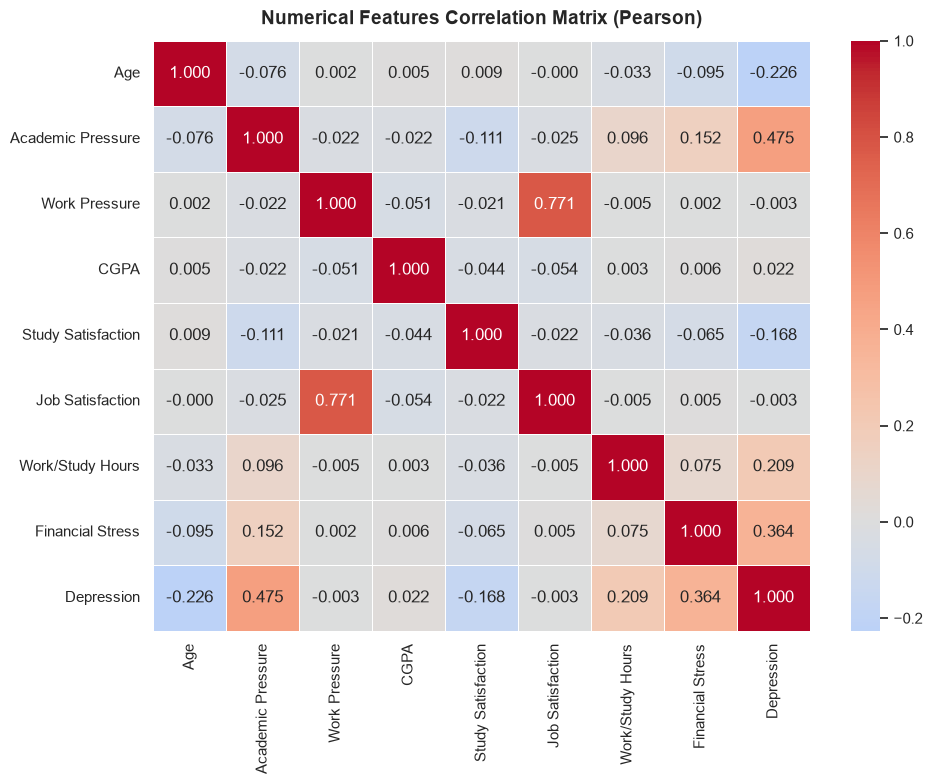

In [10]:
# A. Numerical Correlation Heatmap
num_df = df[numeric_cols + ['Depression']].copy()
num_corr = num_df.corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(num_corr, annot=True, cmap='coolwarm', center=0, fmt='.3f', linewidths=0.5)
plt.title("Numerical Features Correlation Matrix (Pearson)", fontsize=14, fontweight='bold', pad=12)
plt.show()


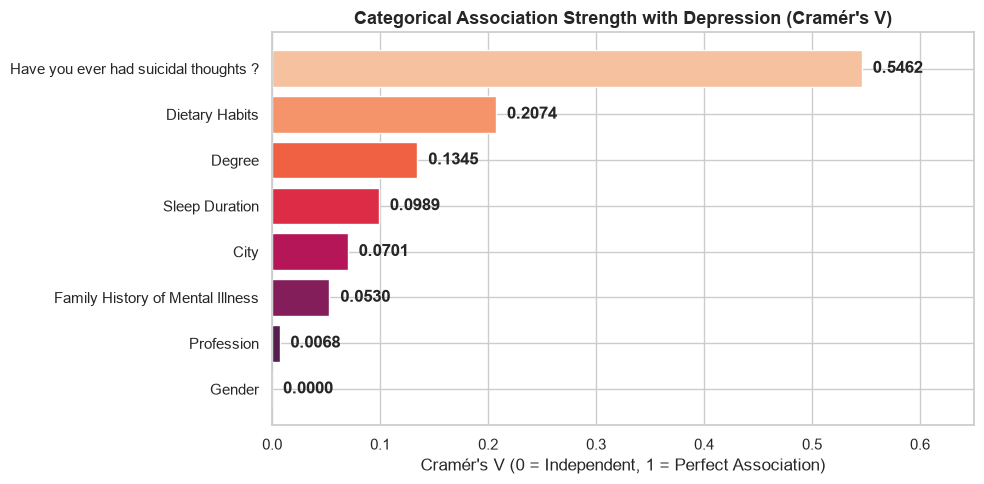

In [11]:
# B. Categorical Association with Depression (Cramer's V)
def calculate_cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    denom = min((kcorr-1), (rcorr-1))
    if denom <= 0:
        return 0.0
    return np.sqrt(phi2corr / denom)

cat_eval = ['Have you ever had suicidal thoughts ?', 'Dietary Habits', 'Degree', 'Sleep Duration', 'City', 'Family History of Mental Illness', 'Profession', 'Gender']
cramers_scores = {col: calculate_cramers_v(df[col].astype(str), df['Depression']) for col in cat_eval}
cramers_series = pd.Series(cramers_scores).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
bars = plt.barh(cramers_series.index, cramers_series.values, color=sns.color_palette('rocket', len(cramers_series)))
plt.title("Categorical Association Strength with Depression (Cramér's V)", fontsize=13, fontweight='bold')
plt.xlabel("Cramér's V (0 = Independent, 1 = Perfect Association)")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.01, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va='center', fontweight='bold')
plt.xlim(0, 0.65)
plt.show()


## 5. Feature Separation & Missing Value Imputation

In [12]:
X = df.drop(columns=['Depression', 'id']).copy()
y = df['Depression'].copy()

# Inspect numerical correlations with y
num_cols_X = X.select_dtypes(include='number').columns.tolist()
print("Numerical Columns:", num_cols_X)
for c in num_cols_X:
    print(f"Corr for: {c} -> {X[c].corr(y):.4f}")


Numerical Columns: ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress']
Corr for: Age -> -0.2264
Corr for: Academic Pressure -> 0.4748
Corr for: Work Pressure -> -0.0034
Corr for: CGPA -> 0.0222
Corr for: Study Satisfaction -> -0.1680
Corr for: Job Satisfaction -> -0.0035
Corr for: Work/Study Hours -> 0.2086
Corr for: Financial Stress -> 0.3636


In [13]:
# Check missing values
print("Missing values per column:")
print(X.isnull().sum())

# Impute Financial Stress with median
financial_median = X['Financial Stress'].median()
X['Financial Stress'] = X['Financial Stress'].fillna(financial_median)
print(f"\nImputed Financial Stress using median: {financial_median}")
print("Remaining missing values in Financial Stress:", X['Financial Stress'].isnull().sum())


Missing values per column:
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         3
Family History of Mental Illness         0
dtype: int64

Imputed Financial Stress using median: 3.0
Remaining missing values in Financial Stress: 0


## 6. Preprocessing & Feature Encoding
Maintaining team assignments and exact transformations:
- **Irish May Pureza:** One-Hot encode Gender, City, Profession; Map Sleep Duration
- **Julia Lois Mendoza:** Map Dietary Habits, LabelEncode Degree, Map Boolean columns


In [14]:
# ==========================================
# Task: Irish May Pureza
# ==========================================
"""
To Irish May Pureza

Convert Gender, City, Profession, and Sleep Duration from Categorical to Numerical

To check:
1. Run X.head() and see the values of Gender, City, Profession, and Sleep Duration
2. Run X['Gender'].value_counts(), it should now be numerical
3. Run X['City'].value_counts(), it should now be numerical
4. Run X['Profession'].value_counts(), it should now be numerical
5. Run X['Sleep Duration'].value_counts(), it should now be numerical
6. Check X.dtypes to check the types of the columns
"""

one_hot_cat_cols = ['Gender', 'City', 'Profession']
X = pd.get_dummies(X, columns=one_hot_cat_cols, drop_first=True)

sleep_mapping = {
    "Less than 5 hours": 0,
    "5-6 hours": 1,
    "7-8 hours": 2,
    "More than 8 hours": 3
}
X['Sleep Duration'] = X['Sleep Duration'].replace({'Others': '5-6 hours'})
X['Sleep Duration'] = X['Sleep Duration'].str.strip().map(sleep_mapping)

print("Irish's task completed. Sleep Duration value counts:")
print(X['Sleep Duration'].value_counts())


Irish's task completed. Sleep Duration value counts:
Sleep Duration
0    8310
2    7346
1    6201
3    6044
Name: count, dtype: int64


In [15]:
# ==========================================
# Task: Julia Lois Mendoza
# ==========================================
"""
To Julia Lois Mendoza

Convert Dietary Habits, Degree, Have you ever had suicidal thoughts ?,
and Family History of Mental Illness from Categorical to Numerical

To check:
1. Run X.head() and see the values of Dietary Habits, Degree,
Have you ever had suicidal thoughts ?, and Family History of Mental Illness
2. Run X['Dietary Habits'].value_counts(), it should now be numerical
3. Run X['Degree'].value_counts(), it should now be numerical
4. Run X['Have you ever had suicidal thoughts ?'].value_counts(), it should now be numerical
5. Run X['Family History of Mental Illness'].value_counts(), it should now be numerical
6. Check X.dtypes to check the types of the columns
"""

X['Dietary Habits'] = X['Dietary Habits'].replace({'Others': 'Healthy'})
diet_mapping = {
    "Unhealthy": 0,
    "Moderate": 1,
    "Healthy": 2
}
X['Dietary Habits'] = X['Dietary Habits'].map(diet_mapping)

# One-Hot / Label encode Degree
le = LabelEncoder()
X['Degree'] = le.fit_transform(X['Degree'].astype(str))

# Map boolean indicators to 0 and 1
boolean_map = {"No": 0, "Yes": 1}
bool_cols = ['Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']
for col in bool_cols:
    X[col] = X[col].map(boolean_map)

print("Julia's task completed. Verifying data types:")
print(X.dtypes.value_counts())


Julia's task completed. Verifying data types:
bool       65
int64      11
float64     2
Name: count, dtype: int64


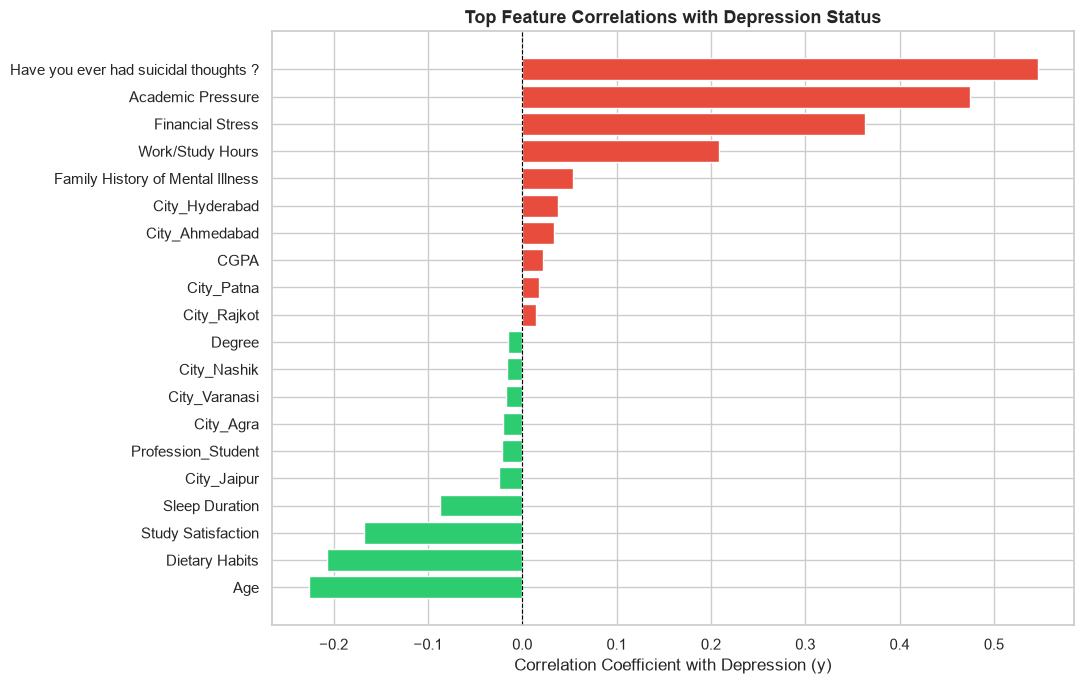

In [16]:
# Full correlation of all transformed features with target y
correlations = X.corrwith(y).sort_values()

# Plot Top Positive and Negative Correlated Features
top_features = pd.concat([correlations.head(10), correlations.tail(10)])

plt.figure(figsize=(11, 7))
bar_colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in top_features.values]
plt.barh(top_features.index, top_features.values, color=bar_colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title("Top Feature Correlations with Depression Status", fontsize=13, fontweight='bold')
plt.xlabel("Correlation Coefficient with Depression (y)")
plt.show()


## 7. Train-Validation Split & Feature Scaling

In [17]:
# 80/20 train-validation split (random_state=84)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=84
)

# Standard scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_val shape  : {X_val_scaled.shape}")


X_train shape: (22320, 78)
X_val shape  : (5581, 78)


## 8. Model Training & Local Validation Dashboard

In [18]:
# Train Logistic Regression model
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

# Predict on validation set
val_preds = model.predict(X_val_scaled)

# Validation metrics
val_acc = accuracy_score(y_val, val_preds)
val_precision = precision_score(y_val, val_preds)
val_recall = recall_score(y_val, val_preds)
val_f1 = f1_score(y_val, val_preds)

# Baseline comparison (Majority class)
majority_count = y_val.value_counts().max()
val_baseline_acc = majority_count / len(y_val)

print("=" * 55)
print("===== LOCAL VALIDATION & BASELINE DASHBOARD =====")
print("=" * 55)
print(f"Majority Baseline Acc: {val_baseline_acc:.4f} ({val_baseline_acc * 100:.2f}%)")
print(f"Model Accuracy       : {val_acc:.4f} ({val_acc * 100:.2f}%) [+{((val_acc - val_baseline_acc) * 100):.2f}% vs baseline]")
print(f"Precision            : {val_precision:.4f} ({val_precision * 100:.2f}%)")
print(f"Sensitivity (Recall) : {val_recall:.4f} ({val_recall * 100:.2f}%)")
print(f"F1-Score             : {val_f1:.4f}")
print("=" * 55)


===== LOCAL VALIDATION & BASELINE DASHBOARD =====
Majority Baseline Acc: 0.5762 (57.62%)
Model Accuracy       : 0.8556 (85.56%) [+27.93% vs baseline]
Precision            : 0.8612 (86.12%)
Sensitivity (Recall) : 0.8933 (89.33%)
F1-Score             : 0.8770


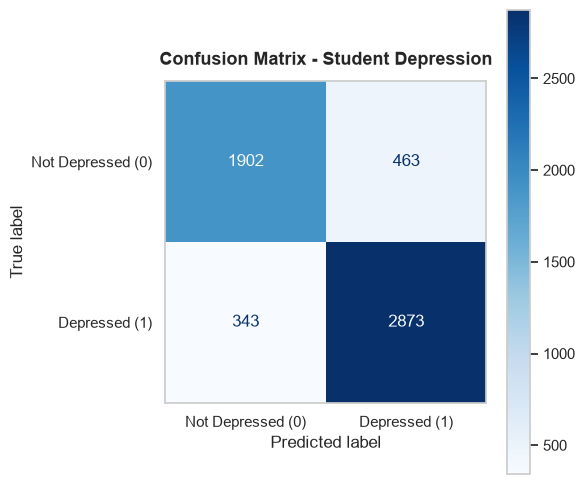

In [19]:
# Confusion Matrix Visualization
cm = confusion_matrix(y_val, val_preds)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Depressed (0)', 'Depressed (1)']
)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Confusion Matrix - Student Depression", fontsize=13, fontweight='bold', pad=12)
plt.grid(False)
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/09_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


## 9. Evaluation Metrics & Classification Outcomes Breakdown Table

Structured summary of the model evaluation metrics (with baseline comparison) and the classification error analysis breakdown (True Positives, True Negatives, False Positives, False Negatives).

In [20]:
# Compute exact classification outcomes
tn, fp, fn, tp = cm.ravel()
total = len(y_val)

# 1. Evaluation Metrics Summary DataFrame
metrics_summary = pd.DataFrame({
    'Metric': ['Majority Baseline', 'Accuracy', 'Precision', 'Sensitivity (Recall)', 'F1-Score'],
    'Score': [
        f"{val_baseline_acc:.4f} ({val_baseline_acc * 100:.2f}%)",
        f"{val_acc:.4f} ({val_acc * 100:.2f}%)",
        f"{val_precision:.4f} ({val_precision * 100:.2f}%)",
        f"{val_recall:.4f} ({val_recall * 100:.2f}%)",
        f"{val_f1:.4f}"
    ],
    'Definition / Clinical Interpretation': [
        'Benchmark guessing majority class (1)',
        f'Overall correct predictions ({tp + tn:,} / {total:,})',
        f'Reliability of positive depression flags ({tp:,} / {tp + fp:,})',
        f'True depressed students detected ({tp:,} / {tp + fn:,})',
        'Harmonic balance of precision and recall'
    ]
})

# 2. Classification Outcomes (Error Analysis) DataFrame
outcomes_summary = pd.DataFrame({
    'Outcome Category': ['True Positives (TP)', 'True Negatives (TN)', 'False Positives (FP)', 'False Negatives (FN)', 'Total Validation'],
    'Predicted Label': ['Depressed (1)', 'Not Depressed (0)', 'Depressed (1)', 'Not Depressed (0)', 'Held-out Sample'],
    'Actual Label': ['Depressed (1)', 'Not Depressed (0)', 'Not Depressed (0)', 'Depressed (1)', 'Combined Classes'],
    'Count': [f"{tp:,}", f"{tn:,}", f"{fp:,}", f"{fn:,}", f"{total:,}"],
    'Percentage': [f"{tp/total*100:.2f}%", f"{tn/total*100:.2f}%", f"{fp/total*100:.2f}%", f"{fn/total*100:.2f}%", '100.00%'],
    'Clinical Significance': ['Correctly Flagged', 'Correctly Cleared', 'False Alarm Error', 'Missed Case Error', f'{val_acc*100:.2f}% Overall Acc.']
})

print("=== TABLE 1: MODEL EVALUATION METRICS ===")
display(metrics_summary)

print("\n=== TABLE 2: CLASSIFICATION OUTCOMES BREAKDOWN (ERROR ANALYSIS) ===")
display(outcomes_summary)

# ---------------------------------------------
# Figure 1: Model Performance & Baseline Comparison Table
# ---------------------------------------------
fig1, ax1 = plt.subplots(figsize=(11, 4.0), dpi=300)
fig1.patch.set_facecolor('white')
ax1.axis('off')
ax1.set_title('Model Performance & Baseline Comparison', fontsize=13, fontweight='bold', pad=16)
table1 = ax1.table(
    cellText=metrics_summary.values,
    colLabels=metrics_summary.columns,
    colWidths=[0.24, 0.22, 0.54],
    loc='center',
    cellLoc='left'
)
table1.auto_set_font_size(False)
table1.set_fontsize(10)
table1.scale(1.0, 2.2)
for (row, col), cell in table1.get_celld().items():
    cell.set_edgecolor('black')
    cell.set_linewidth(1.0)
    if row == 0:
        cell.set_facecolor('#f0f0f0')
        cell.set_text_props(weight='bold', ha='center')
    elif row == 1:
        cell.set_facecolor('#fafafa')
        cell.set_text_props(color='#444444')
    else:
        cell.set_facecolor('white')
    if col == 1:
        cell.set_text_props(ha='center')

plt.tight_layout()
plt.savefig('figures/15_model_performance_table.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------
# Figure 2: Classification Outcomes Breakdown (Error Analysis) Table
# ---------------------------------------------
fig2, ax2 = plt.subplots(figsize=(11, 4.2), dpi=300)
fig2.patch.set_facecolor('white')
ax2.axis('off')
ax2.set_title('Classification Outcomes Breakdown (Error Analysis)', fontsize=13, fontweight='bold', pad=16)
table2 = ax2.table(
    cellText=outcomes_summary.values,
    colLabels=outcomes_summary.columns,
    colWidths=[0.24, 0.16, 0.16, 0.12, 0.12, 0.20],
    loc='center',
    cellLoc='center'
)
table2.auto_set_font_size(False)
table2.set_fontsize(9.5)
table2.scale(1.0, 2.0)
for (row, col), cell in table2.get_celld().items():
    cell.set_edgecolor('black')
    cell.set_linewidth(1.0)
    if row == 0:
        cell.set_facecolor('#f0f0f0')
        cell.set_text_props(weight='bold')
    elif row == 3:  # FP
        cell.set_facecolor('#fff5f5')
    elif row == 4:  # FN
        cell.set_facecolor('#fff0f0')
    elif row == 5:  # Total
        cell.set_facecolor('#f0f0f0')
        cell.set_text_props(weight='bold')
    else:
        cell.set_facecolor('white')

plt.tight_layout()
plt.savefig('figures/16_classification_outcomes_table.png', dpi=300, bbox_inches='tight')
plt.show()
